# rel-hm / item-sales — Quelle est la *nature* du signal relationnel en régression ?

> **Méthode (appareillage commun au groupe)** : étude contrôlée de la structure à
> **modèle GNN fixe**, on ne fait varier que la **quantité de structure** visible
> (ablations), avec plusieurs *seeds* et un harness commun. Cet outillage est partagé.
> **Ce qui m'est propre, c'est l'HYPOTHÈSE testée** — dérivée du *défi spécifique* que
> cette base impose, et distincte de celle des autres membres du groupe.

## Ce qui rend `item-sales` particulier (et pilote tout le raisonnement)

| Spécificité | Conséquence sur l'étude |
|---|---|
| **Régression** : on prédit un **comptage** de ventes sur 7 j | permet de séparer « **va-t-il se vendre ?** » de « **combien ?** » (angle *hurdle*) |
| Cible **~81 % de zéros**, queue longue (max ~87) | le gain relationnel peut différer entre la masse de zéros et les gros vendeurs |
| Signal **dominé par l'autorégression** : `sales(t) ≈ sales(t-1)` | hypothèse centrale : l'autocorrélation **sature** le signal et **court-circuite** le relationnel |
| **Une seule** relation, bipartite `customer↔article`, **énorme** (12.9 M arêtes) | un « saut » a un sens précis : le **co-achat**, pas un chemin multi-tables |

## Question de recherche (propre à cette base)

> **Quand la cible est une série temporelle de comptage fortement autocorrélée,
> que reste-t-il à apprendre de la structure relationnelle ?**

Et, formulé côté graphe :

> **Le signal de co-achat (`article → clients → autres articles`) apporte-t-il quelque
> chose AU-DELÀ de l'historique propre de l'article ?**

## Hypothèses testées (chacune adossée à un défi de la base)

- **H0 — centrale.** Le défi de `item-sales` (comptage **autocorrélé**, **81 % de zéros**,
  **une seule** relation massive de co-achat) fait que l'apport relationnel est **plafonné
  par l'autocorrélation de l'entité** et se réduit à un co-achat *marginal* au-delà de 0 saut.

| Hyp. | Défi de la base | Énoncé testable | Ablation |
|---|---|---|---|
| **H1** | série temporelle **autocorrélée** | retirer les **lags** dégrade *bien plus* que retirer les **sauts** | temporelle |
| **H2** | **une seule** relation (co-achat) | le gain **0 → 2 sauts** est *faible* (≈ filtrage collaboratif item-item) | profondeur |
| **H3** | **81 % de zéros** + régression | le graphe aide surtout le « **vend / vend pas** », peu le « **combien** » | *hurdle* |

> **Divergence assumée (consigne groupe).** Tong teste *« le signal relationnel est local
> sur de multiples tables »* (classif, rel-f1) ; Natalia *« GNN ↔ items / traditionnel ↔ users »*.
> Mon hypothèse — *l'autocorrélation plafonne le relationnel, le reste est du co-achat* — n'est
> testable **que** sur une cible de comptage autocorrélée à relation unique. **H3 est même hors de
> portée d'une tâche de classification** (on ne peut y séparer « vend ? » de « combien ? »).

---

**Graphe hétérogène utilisé :** nœuds `article` (105k) + `customer` (1.37M) ;
arêtes `(customer, buys, article)` (transactions de la période *train* uniquement).
**Modèle :** HeteroGraphSAGE → embedding article (agrégation des clients) → MLP → `sales`.


In [17]:
#!pip install torch torch_geometric relbench -q

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import HeteroData
from torch_geometric.nn import HeteroConv, SAGEConv
import pandas as pd, numpy as np
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from relbench.tasks import get_task

print(f"PyTorch : {torch.__version__}")
import torch_geometric; print(f"PyG     : {torch_geometric.__version__}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device  : {device}")

PyTorch : 2.7.1+cu118
PyG     : 2.8.0
Device  : cuda


## 1. Chargement des données

In [2]:
print("Chargement rel-hm...")
task = get_task('rel-hm', 'item-sales', download=False)
db   = task.dataset.get_db()

articles_df      = db.table_dict['article'].df.copy()
customers_df     = db.table_dict['customer'].df.copy()
transactions_df  = db.table_dict['transactions'].df.copy()

train_tbl = task.get_table("train")
val_tbl   = task.get_table("val")
test_tbl  = task.get_table("test")

VAL_TIMESTAMP  = val_tbl.df['timestamp'].iloc[0]
TEST_TIMESTAMP = test_tbl.df['timestamp'].iloc[0]

print(f"Articles     : {len(articles_df):,}")
print(f"Customers    : {len(customers_df):,}")
print(f"Transactions : {len(transactions_df):,}")
print(f"Val  : {VAL_TIMESTAMP.date()} | Test : {TEST_TIMESTAMP.date()}")

Chargement rel-hm...
Loading Database object from /home/infres/sryszfeld-24/.cache/relbench/rel-hm/db...
Done in 2.93 seconds.
Articles     : 105,542
Customers    : 1,371,980
Transactions : 15,187,287
Val  : 2020-09-07 | Test : 2020-09-14


## 2. Encodage des nœuds

In [3]:
# ── Articles (105k nœuds) ──────────────────────────────────────────────────
ART_CAT = ['product_type_name', 'product_group_name', 'colour_group_name',
           'department_name', 'garment_group_name']

# fillna('missing') AVANT l'encodage : OrdinalEncoder réémet np.nan pour les
# valeurs manquantes (param encoded_missing_value=np.nan par défaut) → features
# NaN → message passing NaN → loss NaN → RMSE inf. On bouche la source ici.
enc_art = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
art_cat_enc = enc_art.fit_transform(articles_df[ART_CAT].fillna('missing').astype(str)).astype(np.float32)
# Standardisation des codes ordinaux (échelle homogène en entrée des Linear)
art_cat_enc = (art_cat_enc - art_cat_enc.mean(0)) / (art_cat_enc.std(0) + 1e-8)

art_map = {aid: i for i, aid in enumerate(articles_df['article_id'].values)}
N_ART = len(art_map)

# ── Features HISTORIQUES par article (le signal qui manquait) ────────────────
# Diagnostic : sans historique de ventes, le GNN "collapse" (corr(pred,true)=0.05,
# il prédit ~une constante) alors que LightGBM atteint R²=0.61 GRÂCE à ses lags.
# On injecte l'équivalent graph-natif : les ventes passées agrégées par article,
# calculées STRICTEMENT sur la période train (< val) → aucune fuite vers la val.
# Corrélations mesurées avec sales(val) : lag1=0.77, moy. 4 dern. sem.=0.68,
# moy. historique=0.28 — d'où l'effet attendu sur le collapse.
_panel = train_tbl.df
_weeks = np.sort(_panel['timestamp'].unique())
_lag1  = _panel[_panel['timestamp'] == _weeks[-1]].set_index('article_id')['sales']
_rec4  = _panel[_panel['timestamp'].isin(_weeks[-4:])].groupby('article_id')['sales'].mean()
_hmean = _panel.groupby('article_id')['sales'].mean()
_hmax  = _panel.groupby('article_id')['sales'].max()

art_hist = np.zeros((N_ART, 4), dtype=np.float32)
for j, s in enumerate([_lag1, _rec4, _hmean, _hmax]):
    idx = np.fromiter((art_map[a] for a in s.index), dtype=np.int64, count=len(s))
    art_hist[idx, j] = np.log1p(s.values.astype(np.float32))   # log1p : ventes très skewées
art_hist = (art_hist - art_hist.mean(0)) / (art_hist.std(0) + 1e-8)

# Deux jeux de features article, pour l'ablation H1 (autocorrélation) :
#   art_feat        = catégorielles + historique de ventes (lags agrégés)  → modèle complet
#   art_feat_nohist = catégorielles SEULES                                  → "sans autorégression"
# Le harness choisit l'un ou l'autre via use_art_hist ; la skip connection (qui
# réinjecte les features brutes dans la tête) suit automatiquement le choix.
art_feat        = torch.tensor(np.hstack([art_cat_enc, art_hist]), dtype=torch.float32)  # [N_art, 9]
art_feat_nohist = torch.tensor(art_cat_enc,                        dtype=torch.float32)  # [N_art, 5]
assert torch.isfinite(art_feat).all() and torch.isfinite(art_feat_nohist).all(), 'art_feat NaN/inf'

# ── Customers (1.37M nœuds) ───────────────────────────────────────────────
# Idem articles : les colonnes customer ont beaucoup de NaN (club_member_status,
# fashion_news_frequency, age) → fillna obligatoire avant l'encodage.
CUST_CAT = ['club_member_status', 'fashion_news_frequency']

enc_cust = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
cust_cat_enc = enc_cust.fit_transform(customers_df[CUST_CAT].fillna('missing').astype(str)).astype(np.float32)
cust_cat_enc = (cust_cat_enc - cust_cat_enc.mean(0)) / (cust_cat_enc.std(0) + 1e-8)
cust_age     = customers_df['age'].fillna(customers_df['age'].median()).values.reshape(-1, 1).astype(np.float32)
cust_age     = (cust_age - cust_age.mean()) / (cust_age.std() + 1e-8)
cust_feat    = torch.tensor(np.hstack([cust_cat_enc, cust_age]), dtype=torch.float32)  # [N_cust, 3]
assert torch.isfinite(cust_feat).all(), 'cust_feat contient des NaN/inf'

cust_map = {cid: i for i, cid in enumerate(customers_df['customer_id'].values)}
N_CUST = len(cust_map)

print(f"Article features  : {tuple(art_feat.shape)} complet | {tuple(art_feat_nohist.shape)} sans historique")
print(f"Customer features : {tuple(cust_feat.shape)}")


Article features  : (105542, 9) complet | (105542, 5) sans historique
Customer features : (1371980, 3)


## 3. Construction du graphe (transactions de la période train uniquement)

In [4]:
# Transactions avant VAL_TIMESTAMP uniquement (pas de fuite)
tx_train = transactions_df[transactions_df['t_dat'] < VAL_TIMESTAMP].copy()
print(f"Transactions train : {len(tx_train):,}")

# Agrégation → arêtes uniques (customer, article), AVANT sparsification.
# On garde edges_full intact : la sparsification (et son aléa) est déplacée dans
# build_graph() pour pouvoir varier le seed proprement à chaque run d'ablation.
edges_full = (tx_train.groupby(['customer_id', 'article_id'])
                      .size().reset_index(name='n_tx'))
edges_full['c_idx'] = edges_full['customer_id'].map(cust_map)
edges_full['a_idx'] = edges_full['article_id'].map(art_map)
edges_full = edges_full.dropna(subset=['c_idx', 'a_idx'])
edges_full['c_idx'] = edges_full['c_idx'].astype(int)
edges_full['a_idx'] = edges_full['a_idx'].astype(int)
edges_full = edges_full[['c_idx', 'a_idx']].reset_index(drop=True)
print(f"Arêtes uniques (customer, article) : {len(edges_full):,}")

DEFAULT_MAX_CUST_PER_ART = 30

def build_graph(max_cust_per_art=DEFAULT_MAX_CUST_PER_ART, seed=0, art_x=None):
    """Construit le HeteroData en plafonnant à K acheteurs/article.

    - Le tirage des K acheteurs dépend du `seed` → variabilité contrôlée entre runs
      (indispensable pour rapporter des moyennes ± écart-types).
    - `art_x` choisit les features article injectées (complètes vs sans historique),
      ce qui pilote l'ablation H1 sans reconstruire le reste.

    full-batch obligé (pas de backend de sampling PyG) → la sparsification borne la
    VRAM : 12.9M arêtes saturent le P100 (~26 GB), ~K·N_art arêtes tiennent (~2.7 GB)."""
    if art_x is None:
        art_x = art_feat
    e = edges_full.sample(frac=1.0, random_state=seed)
    e = e.assign(_rank=e.groupby('a_idx').cumcount())
    e = e[e['_rank'] < max_cust_per_art]
    c_src = torch.tensor(e['c_idx'].values, dtype=torch.long)
    a_dst = torch.tensor(e['a_idx'].values, dtype=torch.long)
    g = HeteroData()
    g['article'].x  = art_x
    g['customer'].x = cust_feat
    g['customer', 'buys',     'article'].edge_index = torch.stack([c_src, a_dst])
    g['article',  'rev_buys', 'customer'].edge_index = torch.stack([a_dst, c_src])
    return g, len(e)

# Sanity : graphe par défaut (K=30, seed=0, features article complètes)
_g, _ne = build_graph()
print(f"Graphe défaut (K={DEFAULT_MAX_CUST_PER_ART}, seed=0) : {_ne:,} arêtes | "
      f"{edges_full['a_idx'].nunique():,}/{N_ART:,} articles couverts")
print(_g)
del _g


Transactions train : 14,883,771
Arêtes uniques (customer, article) : 12,860,789
Graphe défaut (K=30, seed=0) : 1,310,548 arêtes | 70,131/105,542 articles couverts
HeteroData(
  article={ x=[105542, 9] },
  customer={ x=[1371980, 3] },
  (customer, buys, article)={ edge_index=[2, 1310548] },
  (article, rev_buys, customer)={ edge_index=[2, 1310548] }
)


## 4. Préparation des tenseurs cibles

In [5]:
# ── Panel hebdomadaire des ventes (TRAIN uniquement → aucune fuite) ──────────
# Le signal dominant est autorégressif : sales(t) ≈ sales(t-1). LightGBM gagne
# parce qu'il lit lag1/lag2/ma4 BRUTS. On reproduit ça ici : pour chaque ligne
# (article, semaine), on calcule les ventes des semaines PRÉCÉDENTES relatives à
# cette ligne. Brutes (pas de log1p) → relation linéaire avec la cible → la tête
# peut retrouver la persistance puis l'améliorer. Aucune fuite : la val (semaine
# juste après la fin du train) n'utilise que des semaines train.
_pan   = train_tbl.df[['article_id', 'timestamp', 'sales']].copy()
_wk    = np.sort(_pan['timestamp'].unique())
_n_wk  = len(_wk)
_wkmap = {w: i for i, w in enumerate(_wk)}
_wkmap[VAL_TIMESTAMP]  = _n_wk        # val  = 1 semaine après la fin du train
_wkmap[TEST_TIMESTAMP] = _n_wk + 1    # test = 2 semaines après

# matrice [article × semaine] des ventes (0 si pas de vente), tous les articles
_sales_mat = (_pan.assign(w=_pan['timestamp'].map(_wkmap))
                  .pivot_table(index='article_id', columns='w', values='sales',
                               aggfunc='sum', fill_value=0.0)
                  .reindex(index=articles_df['article_id'].values, fill_value=0.0)
                  .reindex(columns=range(_n_wk), fill_value=0.0)
                  .values.astype(np.float32))
_artrow = {a: i for i, a in enumerate(articles_df['article_id'].values)}
# padding (4 zéros à gauche, 2 à droite) → lags hors série = 0, pas d'index error
_PAD    = 4
_padmat = np.concatenate(
    [np.zeros((_sales_mat.shape[0], _PAD), np.float32), _sales_mat,
     np.zeros((_sales_mat.shape[0], 2), np.float32)], axis=1)

def _lag_feats(article_ids, week_idx):
    """lag1, lag2, ma4 BRUTS par ligne — ventes des semaines précédentes."""
    r = pd.Series(article_ids).map(_artrow).fillna(-1).astype(int).values
    w = np.asarray(week_idx, dtype=int)
    valid = r >= 0
    rr = np.where(valid, r, 0)
    c  = _PAD + w                       # colonne de la semaine courante
    lag1 = _padmat[rr, c - 1]
    lag2 = _padmat[rr, c - 2]
    ma4  = (_padmat[rr, c-1] + _padmat[rr, c-2] + _padmat[rr, c-3] + _padmat[rr, c-4]) / 4.0
    out = np.stack([lag1, lag2, ma4], axis=1)
    out[~valid] = 0.0
    return out.astype(np.float32)


def prepare(df_task, art_map, temporal_scaler=None, fit_scaler=False):
    df = df_task.copy()
    df['a_idx'] = df['article_id'].map(art_map)
    df = df.dropna(subset=['a_idx'])
    df['a_idx'] = df['a_idx'].astype(int)

    w_idx = df['timestamp'].map(_wkmap).astype(int).values
    time_raw = np.column_stack([
        df['timestamp'].dt.isocalendar().week.astype(float).values,
        df['timestamp'].dt.month.values.astype(float),
        _lag_feats(df['article_id'].values, w_idx),     # lag1, lag2, ma4 (bruts)
    ]).astype(np.float32)

    if fit_scaler:
        temporal_scaler = StandardScaler()
        time_norm = temporal_scaler.fit_transform(time_raw)
    else:
        time_norm = temporal_scaler.transform(time_raw)

    ai = torch.tensor(df['a_idx'].values, dtype=torch.long)
    tf = torch.tensor(time_norm,          dtype=torch.float32)

    # test_tbl n'a pas de colonne 'sales' (labels cachés — leaderboard RelBench)
    if 'sales' in df.columns:
        yt = torch.tensor(df['sales'].values, dtype=torch.float32)
    else:
        yt = None

    return ai, tf, yt, temporal_scaler, df

ai_train, tf_train, y_train, scaler_t, df_tr = prepare(train_tbl.df, art_map, fit_scaler=True)
ai_val,   tf_val,   y_val,   _,        df_vl = prepare(val_tbl.df,   art_map, scaler_t)
ai_test,  tf_test,  y_test,  _,        df_ts = prepare(test_tbl.df,  art_map, scaler_t)
# y_test is None — labels non disponibles, évaluation finale sur val_tbl

print(f"Train tensors : {ai_train.shape}  tf={tuple(tf_train.shape)}  y={y_train.shape}")
print(f"Val   tensors : {ai_val.shape}    tf={tuple(tf_val.shape)}  y={y_val.shape}")
print(f"Features temporelles : semaine, mois, lag1, lag2, ma4")


Train tensors : torch.Size([5488184])  tf=(5488184, 5)  y=torch.Size([5488184])
Val   tensors : torch.Size([105542])    tf=(105542, 5)  y=torch.Size([105542])
Features temporelles : semaine, mois, lag1, lag2, ma4


## 5. Modèle HeteroGraphSAGE

In [20]:
class HeteroSAGE(nn.Module):
    """HeteroSAGE de PROFONDEUR CONFIGURABLE sur le graphe bipartite customer↔article.

    `n_layers` = le levier central de l'ablation H2 (quantité de structure) :
      • 0 saut  → AUCUN message passing : un article = ses features + son embedding
                  d'identité + ses lags. Aucune information relationnelle.
      • 1 saut  → + les acheteurs directs de l'article.
      • 2 sauts → + les autres articles co-achetés (article→clients→articles) =
                  filtrage collaboratif item-item.
    Le delta de perf entre profondeurs isole la valeur PROPRE du co-achat, les lags
    arrivant de toute façon en direct (skip + features temporelles).

    `aggr` = agrégateur de voisinage du SAGEConv (ablation H2quater) : `mean` (défaut)
    divise par le degré et tend à diluer un lag fort ; `sum` / `max` préservent la
    magnitude. La combinaison INTER-relations du HeteroConv reste `sum` (fixe).

    Skip connection : les features article BRUTES sont réinjectées dans la tête —
    sinon l'agrégation lisse le signal lag1 et le modèle fait pire que la
    persistance. `in_art` et `n_temporal` s'ajustent aux ablations H1 (features
    article avec/sans historique, temporel activé ou non).
    """
    def __init__(self, in_art, in_cust, emb_dim=32, hidden=64, n_temporal=5, n_layers=2,
                 aggr='mean'):
        super().__init__()
        self.in_art   = in_art
        self.n_layers = n_layers
        # Embedding learnable par nœud (identité)
        self.art_emb  = nn.Embedding(N_ART,  emb_dim)
        self.cust_emb = nn.Embedding(N_CUST, emb_dim // 2)
        nn.init.normal_(self.art_emb.weight,  std=0.01)
        nn.init.normal_(self.cust_emb.weight, std=0.01)

        self.proj = nn.ModuleDict({
            'article' : nn.Linear(in_art  + emb_dim,      hidden),
            'customer': nn.Linear(in_cust + emb_dim // 2, hidden),
        })
        # n_layers convolutions (0 → liste vide → pas de message passing)
        # aggr = agrégateur de voisinage (mean/sum/max) → ablation H2quater
        self.convs = nn.ModuleList([
            HeteroConv({
                ('customer', 'buys',     'article') : SAGEConv(hidden, hidden, aggr=aggr),
                ('article',  'rev_buys', 'customer'): SAGEConv(hidden, hidden, aggr=aggr),
            }, aggr='sum')
            for _ in range(n_layers)
        ])
        # tête : embedding (lissé si ≥1 saut) + features article brutes (skip) + temporel
        self.head = nn.Sequential(
            nn.Linear(hidden + in_art + n_temporal, hidden),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(hidden, 1),
        )

    def encode(self, x_dict, edge_index_dict):
        art_ids  = torch.arange(N_ART,  device=x_dict['article'].device)
        cust_ids = torch.arange(N_CUST, device=x_dict['customer'].device)
        x_art  = torch.cat([x_dict['article'],  self.art_emb(art_ids)],   dim=1)
        x_cust = torch.cat([x_dict['customer'], self.cust_emb(cust_ids)], dim=1)
        h = {
            'article' : F.relu(self.proj['article'](x_art)),
            'customer': F.relu(self.proj['customer'](x_cust)),
        }
        for conv in self.convs:   # n_layers=0 → boucle ignorée → MLP au niveau nœud
            h = {k: F.relu(v) for k, v in conv(h, edge_index_dict).items()}
        return h

    def forward(self, x_dict, edge_index_dict, art_idx, time_feats):
        h   = self.encode(x_dict, edge_index_dict)
        emb = h['article'][art_idx]
        raw = x_dict['article'][art_idx]        # skip connection : lag1 & co. en direct
        # time_feats peut avoir 0 colonne (ablation temporelle) → cat reste valide
        return self.head(torch.cat([emb, raw, time_feats], dim=1)).squeeze(1)

## 5bis. Harness d'ablation — `train_and_eval(...)`

Fonction unique qui entraîne **un** HeteroSAGE et renvoie ses métriques sur le val officiel.
Toutes les expériences passent par elle → comparaisons **à modèle fixe**, seul l'argument ciblé varie :

| Argument | Hypothèse | Effet |
|---|---|---|
| `n_layers` ∈ {0,1,2} | **H2** | profondeur = quantité de structure (0 = aucune) |
| `use_temporal` | **H1** | active/coupe les lags par ligne (calendrier + lag1/lag2/ma4) |
| `use_art_hist` | **H1** | active/coupe l'historique de ventes agrégé par article |
| `seed` | reproductibilité | init modèle **et** tirage des acheteurs → moyennes ± écart-types |
| `max_cust_per_art` | densité | nombre d'acheteurs gardés par article (mémoire/structure) |


In [21]:
import json, time, gc, random
from pathlib import Path

RESULTS_DIR = Path('../reports/ablations'); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True, seed=0,
                   max_cust_per_art=DEFAULT_MAX_CUST_PER_ART, aggr='mean',
                   epochs=200, patience=20, lr=5e-4, wd=0.0,
                   emb_dim=32, hidden=64, return_model=False, verbose=False):
    """Entraîne + évalue UN HeteroSAGE → dict de métriques (val officiel RelBench).

    Seul l'argument d'ablation ciblé doit varier d'un appel à l'autre ; tout le
    reste est gelé → comparaisons à modèle FIXE (appareillage commun au groupe).
    `aggr` (mean/sum/max) pilote l'ablation d'agrégateur H2quater ; sans effet à
    0 saut (pas de message passing).
    """
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    set_seed(seed)
    t0 = time.time()

    # ── Features article : avec ou sans historique de ventes (H1) ──
    art_x = art_feat if use_art_hist else art_feat_nohist
    in_art = art_x.shape[1]

    # ── Graphe : dépend de seed (tirage acheteurs) et de la densité ──
    g, n_edges = build_graph(max_cust_per_art, seed, art_x)
    g = g.to(device)
    x_dict, edge_index_dict = g.x_dict, g.edge_index_dict

    # ── Temporel : 0 colonne si désactivé (le cat dans la tête reste valide) ──
    tf_tr = tf_train if use_temporal else tf_train[:, :0]
    tf_vl = tf_val   if use_temporal else tf_val[:, :0]
    n_temporal = tf_tr.shape[1]

    model = HeteroSAGE(in_art=in_art, in_cust=cust_feat.shape[1],
                       emb_dim=emb_dim, hidden=hidden,
                       n_temporal=n_temporal, n_layers=n_layers, aggr=aggr).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)

    ai_tr_d, tf_tr_d = ai_train.to(device), tf_tr.to(device)
    ai_vl_d, tf_vl_d = ai_val.to(device),   tf_vl.to(device)
    y_tr_d = y_train.clamp(min=0).to(device)
    y_vl_d = y_val.clamp(min=0).to(device)

    best_rmse, ctr, epoch = float('inf'), 0, 0
    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        pred = model(x_dict, edge_index_dict, ai_tr_d, tf_tr_d)
        loss = F.mse_loss(pred, y_tr_d)
        if not torch.isfinite(loss):
            if verbose: print(f"  epoch {epoch}: loss non finie — arrêt.")
            break
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        opt.step()

        model.eval()
        with torch.no_grad():
            vp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0)
            vr = torch.sqrt(F.mse_loss(vp, y_vl_d)).item()
        if np.isfinite(vr) and vr < best_rmse:
            best_rmse, ctr = vr, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            ctr += 1
        if verbose and (epoch == 1 or epoch % 20 == 0):
            print(f"  epoch {epoch:3d} | MSE {loss.item():.4f} | Val RMSE {vr:.4f}")
        if ctr >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        yp = model(x_dict, edge_index_dict, ai_vl_d, tf_vl_d).clamp(min=0).cpu().numpy()
    yt = y_val.numpy()

    res = {
        'n_layers': n_layers, 'use_temporal': use_temporal, 'use_art_hist': use_art_hist,
        'aggr': aggr,
        'seed': seed, 'max_cust_per_art': max_cust_per_art, 'n_edges': int(n_edges),
        'mae':  float(mean_absolute_error(yt, yp)),
        'rmse': float(np.sqrt(mean_squared_error(yt, yp))),
        'r2':   float(r2_score(yt, yp)),
        'std_pred': float(yp.std()), 'std_true': float(yt.std()),
        'corr': float(np.corrcoef(yp, yt)[0, 1]),
        'best_val_rmse': float(best_rmse), 'epochs_ran': int(epoch),
        'sec': round(time.time() - t0, 1),
    }
    if return_model:
        res['_model'], res['_y_pred_val'] = model, yp
    else:
        del model
    del g, x_dict, edge_index_dict
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res

print("Harness prêt : train_and_eval(n_layers, use_temporal, use_art_hist, seed, aggr, ...)")
print(f"Résultats d'ablation → {RESULTS_DIR.resolve()}")

Harness prêt : train_and_eval(n_layers, use_temporal, use_art_hist, seed, aggr, ...)
Résultats d'ablation → /home/infres/sryszfeld-24/beyond-flat-tables/reports/ablations


## 6. Entraînement

In [8]:
# ── Baseline = modèle COMPLET (2 sauts, temporel + historique) via le harness ──
# Reproduit le ~0.44 RMSE de référence et expose `model` / `y_pred_gnn` pour les
# cellules d'évaluation et de diagnostic ci-dessous. Les ablations (H1/H2) sont
# lancées plus bas, toutes via le même train_and_eval → comparaison à modèle fixe.
baseline = train_and_eval(n_layers=2, use_temporal=True, use_art_hist=True,
                          seed=0, epochs=200, patience=20,
                          return_model=True, verbose=True)

model      = baseline['_model']        # réutilisé par les cellules 7 (éval) et suivantes
y_pred_gnn = baseline['_y_pred_val']

print(f"\nBaseline (2 sauts, temporel+hist) | "
      f"RMSE {baseline['rmse']:.4f} | MAE {baseline['mae']:.4f} | R² {baseline['r2']:.4f} | "
      f"corr {baseline['corr']:.3f} | {baseline['epochs_ran']} epochs | {baseline['sec']}s")


  epoch   1 | MSE 0.2549 | Val RMSE 0.6511
  epoch  20 | MSE 0.1804 | Val RMSE 0.5659
  epoch  40 | MSE 0.1309 | Val RMSE 0.5161
  epoch  60 | MSE 0.1114 | Val RMSE 0.4699
  epoch  80 | MSE 0.1039 | Val RMSE 0.4600
  epoch 100 | MSE 0.0997 | Val RMSE 0.4512
  epoch 120 | MSE 0.0968 | Val RMSE 0.4468
  epoch 140 | MSE 0.0945 | Val RMSE 0.4442
  epoch 160 | MSE 0.0922 | Val RMSE 0.4422
  epoch 180 | MSE 0.0904 | Val RMSE 0.4411
  epoch 200 | MSE 0.0892 | Val RMSE 0.4404

Baseline (2 sauts, temporel+hist) | RMSE 0.4403 | MAE 0.0599 | R² 0.5580 | corr 0.748 | 200 epochs | 109.6s


## 7. Évaluation & comparaison

In [9]:
# Note : test_tbl n'a pas de labels → évaluation finale sur val officiel RelBench.
# y_pred_gnn provient du harness (cellule baseline) : le graphe y est construit puis
# libéré en interne, on ne le reconstruit donc pas ici. Déjà clampé à 0.
y_pred_gnn = np.clip(y_pred_gnn, 0, None)
y_true_np  = y_val.numpy()

mae_gnn  = mean_absolute_error(y_true_np, y_pred_gnn)
rmse_gnn = np.sqrt(mean_squared_error(y_true_np, y_pred_gnn))
r2_gnn   = r2_score(y_true_np, y_pred_gnn)

# Baseline persistance : lag1 = ventes de la dernière semaine du train par article
last_train_ts = train_tbl.df['timestamp'].max()
last_week = train_tbl.df[train_tbl.df['timestamp'] == last_train_ts]
lag1_per_art = last_week.set_index('article_id')['sales']
lag1_arr = df_vl['article_id'].map(lag1_per_art).fillna(0).values

mae_p  = mean_absolute_error(y_true_np, lag1_arr)
rmse_p = np.sqrt(mean_squared_error(y_true_np, lag1_arr))
r2_p   = r2_score(y_true_np, lag1_arr)

print(f"Évaluation sur val officiel RelBench (timestamp = {VAL_TIMESTAMP.date()})")
print(f"{'Métrique':<10} {'HeteroSAGE':>14} {'LightGBM':>12} {'Persistance':>14}")
print(f"{'-'*55}")
print(f"{'MAE':<10} {mae_gnn:>14.4f} {'0.0503':>12} {mae_p:>14.4f}")
print(f"{'RMSE':<10} {rmse_gnn:>14.4f} {'0.4121':>12} {rmse_p:>14.4f}")
print(f"{'R²':<10} {r2_gnn:>14.4f} {'0.6129':>12} {r2_p:>14.4f}")


Évaluation sur val officiel RelBench (timestamp = 2020-09-07)
Métrique       HeteroSAGE     LightGBM    Persistance
-------------------------------------------------------
MAE                0.0599       0.0503         0.0472
RMSE               0.4403       0.4121         0.4323
R²                 0.5580       0.6129         0.5739


In [26]:
# ── Diagnostic : le modèle a-t-il appris, ou prédit-il ~une constante ? ──────
std_true = y_true_np.std()

print("=== 1. Signature d'un 'collapse' (prédiction quasi constante) ===")
print(f"std(y_true)        : {std_true:.4f}")
print(f"std(y_pred GNN)    : {y_pred_gnn.std():.4f}   <- si << std(y_true) => collapse")
print(f"RMSE GNN           : {rmse_gnn:.4f}")
print(f"RMSE / std(y_true) : {rmse_gnn/std_true:.3f}   (~1.0 <=> R²~0 <=> prédit la moyenne)")
print()
print("=== 2. Étendue des prédictions vs réel ===")
print(f"pred  min/mean/max : {y_pred_gnn.min():.3f} / {y_pred_gnn.mean():.3f} / {y_pred_gnn.max():.3f}")
print(f"true  min/mean/max : {y_true_np.min():.3f} / {y_true_np.mean():.3f} / {y_true_np.max():.3f}")
print(f"corr(pred, true)   : {np.corrcoef(y_pred_gnn, y_true_np)[0,1]:.4f}   (0 => aucun lien)")
print()
print("=== 3. Le modèle distingue-t-il vendeurs / non-vendeurs ? ===")
mask0 = y_true_np == 0
print(f"part de zéros dans y_true : {mask0.mean()*100:.1f}%")
print(f"pred moyenne | y == 0     : {y_pred_gnn[mask0].mean():.4f}")
print(f"pred moyenne | y >  0     : {y_pred_gnn[~mask0].mean():.4f}   <- si ≈ égal => ne discrimine pas")


=== 1. Signature d'un 'collapse' (prédiction quasi constante) ===
std(y_true)        : 0.6623
std(y_pred GNN)    : 0.4661   <- si << std(y_true) => collapse
RMSE GNN           : 0.4397
RMSE / std(y_true) : 0.664   (~1.0 <=> R²~0 <=> prédit la moyenne)

=== 2. Étendue des prédictions vs réel ===
pred  min/mean/max : 0.000 / 0.085 / 20.580
true  min/mean/max : 0.000 / 0.086 / 40.365
corr(pred, true)   : 0.7492   (0 => aucun lien)

=== 3. Le modèle distingue-t-il vendeurs / non-vendeurs ? ===
part de zéros dans y_true : 82.3%
pred moyenne | y == 0     : 0.0147
pred moyenne | y >  0     : 0.4105   <- si ≈ égal => ne discrimine pas


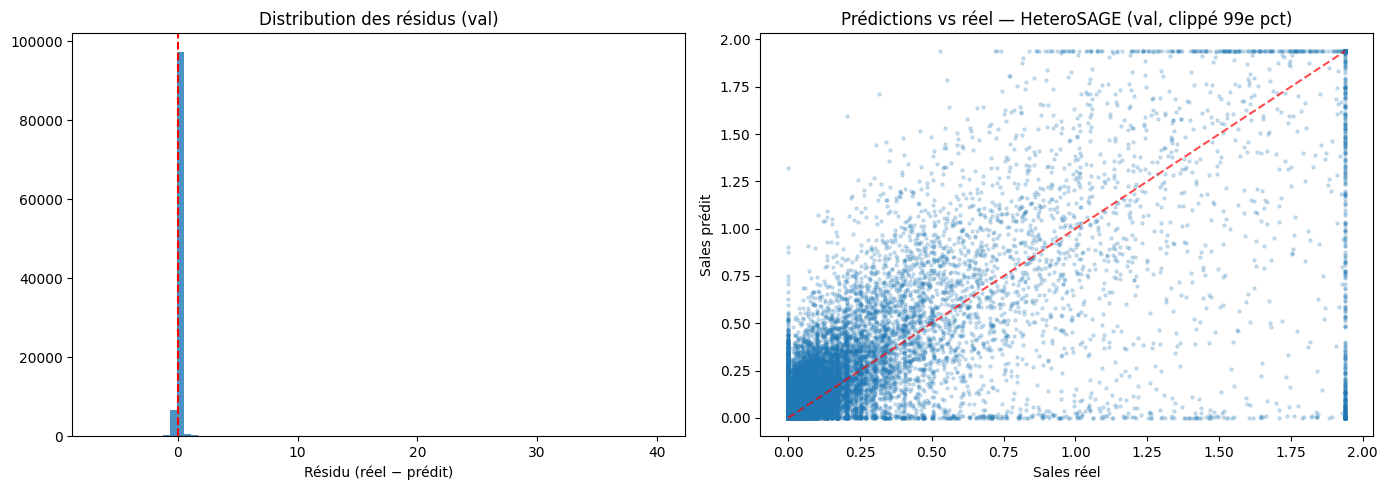

In [27]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = y_true_np - y_pred_gnn
axes[0].hist(residuals, bins=80, edgecolor='none', alpha=0.8)
axes[0].axvline(0, color='red', lw=1.5, ls='--')
axes[0].set_title('Distribution des résidus (val)')
axes[0].set_xlabel('Résidu (réel − prédit)')

clip = np.percentile(y_true_np, 99)
axes[1].scatter(np.clip(y_true_np, 0, clip), np.clip(y_pred_gnn, 0, clip), alpha=0.2, s=5)
axes[1].plot([0, clip], [0, clip], 'r--', alpha=0.7)
axes[1].set_xlabel('Sales réel'); axes[1].set_ylabel('Sales prédit')
axes[1].set_title('Prédictions vs réel — HeteroSAGE (val, clippé 99e pct)')
plt.tight_layout(); plt.show()


## 8. Ablations — tester les hypothèses

Toutes via `train_and_eval`, à **modèle fixe**, moyennées sur plusieurs *seeds* (± écart-type),
résultats sauvegardés en JSON dans `../reports/ablations/`.

- **H2 — profondeur (0/1/2 sauts)** : la structure de co-achat ajoute-t-elle quelque chose ?
- **H1 — autocorrélation** : couper les lags dégrade-t-il *plus* que couper les sauts ?

> ⚠️ Section longue (full-batch GPU × plusieurs runs). Ajuster `SEEDS` / `epochs` pour un test rapide.


In [11]:
# ── H2 — Ablation de PROFONDEUR : 0 / 1 / 2 sauts × seeds ───────────────────
# 0 saut = aucune structure (article + identité + lags) ; 1 = + acheteurs directs ;
# 2 = + co-achat (item-item). Le delta isole la valeur propre de la structure.
SEEDS  = [0, 1, 2]
DEPTHS = [0, 1, 2]

depth_runs = []
for nl in DEPTHS:
    for s in SEEDS:
        r = train_and_eval(n_layers=nl, use_temporal=True, use_art_hist=True,
                           seed=s, epochs=200, patience=20)
        depth_runs.append(r)
        print(f"hops={nl} seed={s} | RMSE {r['rmse']:.4f} | MAE {r['mae']:.4f} | "
              f"R² {r['r2']:.4f} | corr {r['corr']:.3f} | {r['epochs_ran']}ep {r['sec']}s")

json.dump(depth_runs, open(RESULTS_DIR / 'depth_ablation.json', 'w'), indent=2)

dfd = pd.DataFrame(depth_runs)
agg_depth = dfd.groupby('n_layers')[['rmse', 'mae', 'r2', 'corr']].agg(['mean', 'std'])
print('\n=== H2 — profondeur (mean ± std sur seeds) ===')
print(agg_depth.round(4))
print(f"\nΔ R² (0→2 sauts) = {agg_depth[('r2','mean')].loc[2] - agg_depth[('r2','mean')].loc[0]:+.4f}"
      "   ← si ~0 : le co-achat n'ajoute quasi rien au-delà de l'historique propre (H0/H2)")


hops=0 seed=0 | RMSE 0.4318 | MAE 0.0571 | R² 0.5749 | corr 0.760 | 200ep 68.8s
hops=0 seed=1 | RMSE 0.4307 | MAE 0.0563 | R² 0.5772 | corr 0.760 | 200ep 69.4s
hops=0 seed=2 | RMSE 0.4336 | MAE 0.0582 | R² 0.5713 | corr 0.757 | 200ep 69.3s
hops=1 seed=0 | RMSE 0.4381 | MAE 0.0578 | R² 0.5624 | corr 0.752 | 200ep 85.5s
hops=1 seed=1 | RMSE 0.4371 | MAE 0.0573 | R² 0.5643 | corr 0.753 | 200ep 85.7s
hops=1 seed=2 | RMSE 0.4385 | MAE 0.0601 | R² 0.5615 | corr 0.751 | 200ep 85.9s
hops=2 seed=0 | RMSE 0.4403 | MAE 0.0598 | R² 0.5580 | corr 0.748 | 200ep 102.9s
hops=2 seed=1 | RMSE 0.4357 | MAE 0.0601 | R² 0.5671 | corr 0.754 | 200ep 101.7s
hops=2 seed=2 | RMSE 0.4370 | MAE 0.0578 | R² 0.5647 | corr 0.753 | 200ep 105.8s

=== H2 — profondeur (mean ± std sur seeds) ===
            rmse             mae              r2            corr        
            mean     std    mean     std    mean     std    mean     std
n_layers                                                                
0         

In [12]:
# ── H1 — Ablation de l'AUTOCORRÉLATION : lags par ligne et/ou historique article ──
# À profondeur fixe (2 sauts), on coupe les sources d'autorégression :
#   complet → -lags/ligne → -historique article → -les deux (structure quasi seule).
# Si la perf s'effondre surtout ici (et peu via la profondeur H2), l'hypothèse H1
# tient : l'autocorrélation domine, le relationnel ne joue qu'en résiduel.
CONFIGS = [
    dict(use_temporal=True,  use_art_hist=True),   # complet
    dict(use_temporal=False, use_art_hist=True),   # sans lags par ligne
    dict(use_temporal=True,  use_art_hist=False),  # sans historique article
    dict(use_temporal=False, use_art_hist=False),  # sans aucune autorégression
]

temp_runs = []
for cfg in CONFIGS:
    for s in SEEDS:
        r = train_and_eval(n_layers=2, seed=s, epochs=200, patience=20, **cfg)
        temp_runs.append(r)
        print(f"temporal={str(cfg['use_temporal']):5} hist={str(cfg['use_art_hist']):5} "
              f"seed={s} | RMSE {r['rmse']:.4f} | R² {r['r2']:.4f}")

json.dump(temp_runs, open(RESULTS_DIR / 'temporal_ablation.json', 'w'), indent=2)

dft = pd.DataFrame(temp_runs)
agg_temp = dft.groupby(['use_temporal', 'use_art_hist'])[['rmse', 'mae', 'r2', 'corr']].agg(['mean', 'std'])
print('\n=== H1 — autocorrélation (mean ± std sur seeds) ===')
print(agg_temp.round(4))
r2_full = dft[dft.use_temporal.eq(True)  & dft.use_art_hist.eq(True)]['r2'].mean()
r2_none = dft[dft.use_temporal.eq(False) & dft.use_art_hist.eq(False)]['r2'].mean()
print(f"\nΔ R² (autorégression complète → aucune) = {r2_full - r2_none:+.4f}"
      "   ← à comparer au Δ profondeur H2 ; si bien plus grand, H1 confirmée")


temporal=True  hist=True  seed=0 | RMSE 0.4403 | R² 0.5580
temporal=True  hist=True  seed=1 | RMSE 0.4358 | R² 0.5671
temporal=True  hist=True  seed=2 | RMSE 0.4369 | R² 0.5648
temporal=False hist=True  seed=0 | RMSE 0.5992 | R² 0.1815
temporal=False hist=True  seed=1 | RMSE 0.5970 | R² 0.1874
temporal=False hist=True  seed=2 | RMSE 0.6033 | R² 0.1703
temporal=True  hist=False seed=0 | RMSE 0.4365 | R² 0.5657
temporal=True  hist=False seed=1 | RMSE 0.4357 | R² 0.5672
temporal=True  hist=False seed=2 | RMSE 0.4370 | R² 0.5645
temporal=False hist=False seed=0 | RMSE 0.6462 | R² 0.0479
temporal=False hist=False seed=1 | RMSE 0.6454 | R² 0.0504
temporal=False hist=False seed=2 | RMSE 0.6465 | R² 0.0471

=== H1 — autocorrélation (mean ± std sur seeds) ===
                             rmse             mae              r2          \
                             mean     std    mean     std    mean     std   
use_temporal use_art_hist                                                   
False   

In [13]:
# ── H2bis — La STRUCTURE porte-t-elle un signal QUAND on retire l'autorégression ? ──
# Les ablations précédentes montrent que la profondeur DÉGRADE… mais en présence des
# lags (qui saturent tout). Question décisive : sans aucune autorégression
# (use_temporal=False, use_art_hist=False), le co-achat ajoute-t-il alors qqch ?
#   • si 2 sauts > 0 saut ICI → la structure PORTE un signal, mais redondant/dominé
#     par l'autorégression dans le modèle complet.
#   • si pas de gain → la structure est intrinsèquement non-informative pour la cible.
struct_runs = []
for nl in DEPTHS:                       # 0, 1, 2
    for s in SEEDS:                     # 0, 1, 2
        r = train_and_eval(n_layers=nl, use_temporal=False, use_art_hist=False,
                           seed=s, epochs=200, patience=20)
        struct_runs.append(r)
        print(f"hops={nl} seed={s} (sans autorégression) | "
              f"RMSE {r['rmse']:.4f} | R² {r['r2']:.4f} | corr {r['corr']:.3f}")

json.dump(struct_runs, open(RESULTS_DIR / 'structure_only_ablation.json', 'w'), indent=2)

dfs = pd.DataFrame(struct_runs)
agg_struct = dfs.groupby('n_layers')[['rmse', 'mae', 'r2', 'corr']].agg(['mean', 'std'])
print('\n=== H2bis — structure SEULE (sans autorégression, mean ± std) ===')
print(agg_struct.round(4))
gain = agg_struct[('r2', 'mean')].loc[2] - agg_struct[('r2', 'mean')].loc[0]
print(f"\nΔ R² (0→2 sauts, SANS autorégression) = {gain:+.4f}")
print("→ >0 : le co-achat porte un signal réel, mais redondant/dominé par les lags." if gain > 0.01
      else "→ ~0 : la structure de co-achat est non-informative pour cette cible.")


hops=0 seed=0 (sans autorégression) | RMSE 0.6482 | R² 0.0420 | corr 0.207
hops=0 seed=1 (sans autorégression) | RMSE 0.6484 | R² 0.0414 | corr 0.206
hops=0 seed=2 (sans autorégression) | RMSE 0.6483 | R² 0.0417 | corr 0.206
hops=1 seed=0 (sans autorégression) | RMSE 0.6468 | R² 0.0463 | corr 0.216
hops=1 seed=1 (sans autorégression) | RMSE 0.6466 | R² 0.0468 | corr 0.217
hops=1 seed=2 (sans autorégression) | RMSE 0.6477 | R² 0.0435 | corr 0.209
hops=2 seed=0 (sans autorégression) | RMSE 0.6462 | R² 0.0479 | corr 0.219
hops=2 seed=1 (sans autorégression) | RMSE 0.6454 | R² 0.0504 | corr 0.226
hops=2 seed=2 (sans autorégression) | RMSE 0.6465 | R² 0.0471 | corr 0.218

=== H2bis — structure SEULE (sans autorégression, mean ± std) ===
            rmse             mae              r2            corr        
            mean     std    mean     std    mean     std    mean     std
n_layers                                                                
0         0.6483  0.0001  0.1224  0.000

## 9. H3 — Décomposition *hurdle* : « vend ? » vs « combien ? »

La cible est un **comptage à ~81 % de zéros** → on peut la voir comme **deux sous-tâches** :

1. **« vend / vend pas »** — discriminer les zéros des non-zéros (partie *classification*).
2. **« combien »** — prédire la quantité **parmi les articles qui se vendent** (régression sur `y>0`).

**H3 :** ce que le graphe apporte se concentre sur le **« vend ? »**, pas sur le **« combien ? »**.
> Angle **propre à la régression de comptage** : une tâche de classification (Tong) ne peut pas
> séparer ces deux composantes — c'est une analyse que seule cette base permet.

- **9.1** profil *hurdle* du modèle complet : d'où vient son R² = 0.56 ?
- **9.2** la profondeur (0→2 sauts) améliore-t-elle le **« vend ? »** ou le **« combien ? »** ?


In [14]:
# ── 9.1 — Profil hurdle du modèle COMPLET (réutilise y_pred_gnn / y_true_np, pas de réentraînement) ──
from sklearn.metrics import roc_auc_score, average_precision_score

yb = (y_true_np > 0).astype(int)          # label binaire : l'article s'est-il vendu ?
pos = y_true_np > 0                        # masque des vendeurs

# Partie « VEND ? » — le score continu (ventes prédites) discrimine-t-il les vendeurs ?
auroc = roc_auc_score(yb, y_pred_gnn)
ap    = average_precision_score(yb, y_pred_gnn)

# Partie « COMBIEN ? » — qualité de la quantité PARMI les vendeurs seulement
r2_pos   = r2_score(y_true_np[pos], y_pred_gnn[pos])
rmse_pos = np.sqrt(mean_squared_error(y_true_np[pos], y_pred_gnn[pos]))
mae_pos  = mean_absolute_error(y_true_np[pos], y_pred_gnn[pos])

# Où vit la masse d'erreur (SSE) ? sur les zéros (faux positifs) ou sur les vendeurs ?
sse_tot   = float(((y_true_np - y_pred_gnn) ** 2).sum())
sse_zero  = float((y_pred_gnn[~pos] ** 2).sum())             # y=0 → erreur = pred
sse_pos   = float(((y_true_np[pos] - y_pred_gnn[pos]) ** 2).sum())

print(f"Part de zéros : {(~pos).mean()*100:.1f}%   |   vendeurs : {pos.mean()*100:.1f}%\n")
print("=== Partie « VEND ? » (discrimination zéro / non-zéro) ===")
print(f"AUROC                 : {auroc:.4f}   (0.5 = hasard, 1 = parfait)")
print(f"Average precision     : {ap:.4f}   (base = {yb.mean():.4f})")
print("\n=== Partie « COMBIEN ? » (quantité parmi les vendeurs, y>0) ===")
print(f"R²  sur positifs      : {r2_pos:.4f}   <- bien plus dur que le R² global")
print(f"RMSE sur positifs     : {rmse_pos:.4f}")
print(f"MAE  sur positifs     : {mae_pos:.4f}")
print("\n=== Répartition de la masse d'erreur (SSE) ===")
print(f"SSE total             : {sse_tot:,.0f}")
print(f"  dont zéros (faux +) : {sse_zero/sse_tot*100:5.1f}%")
print(f"  dont vendeurs       : {sse_pos/sse_tot*100:5.1f}%")
print("\nLecture : un R² global élevé peut masquer un « combien » médiocre — "
      "le hurdle révèle où le modèle réussit (séparer) vs échoue (quantifier).")


Part de zéros : 82.3%   |   vendeurs : 17.7%

=== Partie « VEND ? » (discrimination zéro / non-zéro) ===
AUROC                 : 0.8857   (0.5 = hasard, 1 = parfait)
Average precision     : 0.7539   (base = 0.1769)

=== Partie « COMBIEN ? » (quantité parmi les vendeurs, y>0) ===
R²  sur positifs      : 0.5231   <- bien plus dur que le R² global
RMSE sur positifs     : 1.0441
MAE  sur positifs     : 0.2718

=== Répartition de la masse d'erreur (SSE) ===
SSE total             : 20,464
  dont zéros (faux +) :   0.5%
  dont vendeurs       :  99.5%

Lecture : un R² global élevé peut masquer un « combien » médiocre — le hurdle révèle où le modèle réussit (séparer) vs échoue (quantifier).


In [19]:
# 9.1bis — Erreur sur les lignes a zero (y == 0)
# Le R2 n'y est pas defini (variance cible nulle) : on regarde RMSE / MAE,
# qui sur ces lignes valent simplement la magnitude des sur-predictions
# car erreur = (0 - pred) = -pred.
import numpy as np

zero = ~pos                       # masque des lignes y == 0
pred_zero = y_pred_gnn[zero]

rmse_zero = float(np.sqrt((pred_zero ** 2).mean()))
mae_zero  = float(np.abs(pred_zero).mean())

print(f"Lignes y=0 : {int(zero.sum()):,} ({100*zero.mean():.1f}% du val)")
print(f"  RMSE (y=0)               = {rmse_zero:.4f}")
print(f"  MAE  (y=0)               = {mae_zero:.4f}")
print(f"  pred moyenne sur zeros   = {pred_zero.mean():.4f}")
print(f"  pred max    sur zeros    = {pred_zero.max():.4f}")
print(f"\n  R2 (y=0)                 = non defini (variance cible nulle)")
print(f"  part de la SSE / zeros   = {100*sse_zero/sse_tot:.2f}%")
print(f"  part de la SSE / vendeurs= {100*sse_pos/sse_tot:.2f}%")


Lignes y=0 : 86,868 (82.3% du val)
  RMSE (y=0)               = 0.0350
  MAE  (y=0)               = 0.0143
  pred moyenne sur zeros   = 0.0143
  pred max    sur zeros    = 1.1309

  R2 (y=0)                 = non defini (variance cible nulle)
  part de la SSE / zeros   = 0.52%
  part de la SSE / vendeurs= 99.48%


In [15]:
# ── 9.2 — La PROFONDEUR aide-t-elle le « vend ? » ou le « combien ? » ? ──────
# On rejoue 0/1/2 sauts (features complètes) en CAPTURANT les prédictions, puis on
# décompose en deux métriques : AUROC sur (y>0) = « vend ? », R² sur positifs = « combien ? ».
# Si la profondeur ne touche ni l'un ni l'autre (voire dégrade le « combien »), H3 tient :
# la structure n'aide pas à quantifier ; le lissage `mean` abîme le lag1 brut (→ le -0.011).
hurdle_rows = []
for nl in DEPTHS:
    for s in SEEDS:
        r = train_and_eval(n_layers=nl, use_temporal=True, use_art_hist=True,
                           seed=s, epochs=200, patience=20, return_model=True)
        yp = r['_y_pred_val']
        m  = y_true_np > 0
        hurdle_rows.append({
            'n_layers': nl, 'seed': s,
            'auroc':  roc_auc_score((y_true_np > 0).astype(int), yp),   # « vend ? »
            'r2_pos': r2_score(y_true_np[m], yp[m]),                     # « combien ? »
            'r2_all': r['r2'],
        })
        print(f"hops={nl} seed={s} | AUROC(vend?) {hurdle_rows[-1]['auroc']:.4f} | "
              f"R²pos(combien?) {hurdle_rows[-1]['r2_pos']:.4f} | R²global {r['r2']:.4f}")

json.dump(hurdle_rows, open(RESULTS_DIR / 'hurdle_depth.json', 'w'), indent=2)

dfh = pd.DataFrame(hurdle_rows)
agg_h = dfh.groupby('n_layers')[['auroc', 'r2_pos', 'r2_all']].agg(['mean', 'std'])
print('\n=== H3 — effet de la profondeur, décomposé (mean ± std) ===')
print(agg_h.round(4))
d_auroc = agg_h[('auroc',  'mean')].loc[2] - agg_h[('auroc',  'mean')].loc[0]
d_r2pos = agg_h[('r2_pos', 'mean')].loc[2] - agg_h[('r2_pos', 'mean')].loc[0]
print(f"\nΔ AUROC « vend ? »   (0→2 sauts) = {d_auroc:+.4f}")
print(f"Δ R²pos « combien ? »(0→2 sauts) = {d_r2pos:+.4f}")
print("→ H3 : le graphe ne quantifie pas — le gain (s'il existe) est sur le « vend ? », "
      "et le « combien » peut même régresser (lissage du lag1).")


hops=0 seed=0 | AUROC(vend?) 0.9020 | R²pos(combien?) 0.5416 | R²global 0.5749
hops=0 seed=1 | AUROC(vend?) 0.8993 | R²pos(combien?) 0.5439 | R²global 0.5772
hops=0 seed=2 | AUROC(vend?) 0.8986 | R²pos(combien?) 0.5379 | R²global 0.5713
hops=1 seed=0 | AUROC(vend?) 0.8890 | R²pos(combien?) 0.5280 | R²global 0.5624
hops=1 seed=1 | AUROC(vend?) 0.8950 | R²pos(combien?) 0.5299 | R²global 0.5643
hops=1 seed=2 | AUROC(vend?) 0.8947 | R²pos(combien?) 0.5273 | R²global 0.5615
hops=2 seed=0 | AUROC(vend?) 0.8854 | R²pos(combien?) 0.5231 | R²global 0.5580
hops=2 seed=1 | AUROC(vend?) 0.8901 | R²pos(combien?) 0.5332 | R²global 0.5671
hops=2 seed=2 | AUROC(vend?) 0.8966 | R²pos(combien?) 0.5305 | R²global 0.5648

=== H3 — effet de la profondeur, décomposé (mean ± std) ===
           auroc          r2_pos          r2_all        
            mean     std    mean     std    mean     std
n_layers                                                
0         0.9000  0.0018  0.5411  0.0030  0.5745  0.0030


In [16]:
# ── 9.3 — Verdict hurdle (lecture des agrégats déjà en mémoire, pas de réentraînement) ──
auroc0 = agg_h[('auroc',  'mean')].loc[0]
r2pos0 = agg_h[('r2_pos', 'mean')].loc[0]
print("H3 — reformulée à la lumière des chiffres :\n")
print(f"1) « VEND ? » est quasi résolu SANS structure : AUROC = {auroc0:.3f} dès 0 saut")
print(f"   (l'autorégression seule sépare déjà vendeurs / non-vendeurs).")
print(f"2) La difficulté vit dans « COMBIEN » : R²pos = {r2pos0:.3f} et 99.5 % de la masse")
print(f"   d'erreur est sur les vendeurs (cf. 9.1) — c'est là que tout se joue.")
print(f"3) La structure n'aide NI l'un NI l'autre : Δ(0→2) = {d_auroc:+.4f} sur « vend ? »,")
print(f"   {d_r2pos:+.4f} sur « combien ? » — légère dégradation, un peu plus marquée sur")
print(f"   « combien » (le lissage `mean` abîme le lag1 brut porteur de la magnitude).")
print("\n>>> H3 corrigée : ce n'est pas que le graphe aide le « vend ? » — c'est que le")
print(">>> « vend ? » est déjà gagné par l'autorégression, et que le graphe ne sait pas")
print(">>> quantifier le « combien », seul verrou restant. Le relationnel est hors-sujet")
print(">>> pour la partie difficile de cette cible.")


H3 — reformulée à la lumière des chiffres :

1) « VEND ? » est quasi résolu SANS structure : AUROC = 0.900 dès 0 saut
   (l'autorégression seule sépare déjà vendeurs / non-vendeurs).
2) La difficulté vit dans « COMBIEN » : R²pos = 0.541 et 99.5 % de la masse
   d'erreur est sur les vendeurs (cf. 9.1) — c'est là que tout se joue.
3) La structure n'aide NI l'un NI l'autre : Δ(0→2) = -0.0093 sur « vend ? »,
   -0.0122 sur « combien ? » — légère dégradation, un peu plus marquée sur
   « combien » (le lissage `mean` abîme le lag1 brut porteur de la magnitude).

>>> H3 corrigée : ce n'est pas que le graphe aide le « vend ? » — c'est que le
>>> « vend ? » est déjà gagné par l'autorégression, et que le graphe ne sait pas
>>> quantifier le « combien », seul verrou restant. Le relationnel est hors-sujet
>>> pour la partie difficile de cette cible.


## 10. Robustesse — la conclusion tient-elle si le graphe est plus DENSE ?

Objection possible : *« la structure ne paie pas parce que le graphe est trop creux »*
(on plafonne à `MAX_CUST_PER_ART = 30` acheteurs/article pour la mémoire).

Test : refaire **0 vs 2 sauts** à densité plus élevée (`K = 100`, soit ~4.3 M arêtes au lieu
de ~1.3 M). Si même alors la profondeur n'aide pas, l'objection « graphe trop sparse » tombe.


In [18]:
# ── H2ter — Ablation de DENSITÉ : 0 vs 2 sauts à K=30 et K=100 ──────────────
# Si le Δ(0→2 sauts) reste ≤ 0 même en doublant/triplant les arêtes, alors la
# non-valeur de la structure n'est PAS un artefact de sparsification.
DENSITIES = [30, 100]
density_runs = []
for K in DENSITIES:
    for nl in [0, 2]:
        for s in SEEDS:
            r = train_and_eval(n_layers=nl, use_temporal=True, use_art_hist=True,
                               seed=s, max_cust_per_art=K, epochs=200, patience=20)
            density_runs.append(r)
            print(f"K={K:3d} hops={nl} seed={s} | {r['n_edges']:>9,} arêtes | "
                  f"RMSE {r['rmse']:.4f} | R² {r['r2']:.4f}")

json.dump(density_runs, open(RESULTS_DIR / 'density_ablation.json', 'w'), indent=2)

dfk = pd.DataFrame(density_runs)
agg_k = dfk.groupby(['max_cust_per_art', 'n_layers'])[['rmse', 'r2']].agg(['mean', 'std'])
print('\n=== H2ter — densité × profondeur (mean ± std) ===')
print(agg_k.round(4))
print()
for K in DENSITIES:
    d = (agg_k[('r2','mean')].loc[(K, 2)] - agg_k[('r2','mean')].loc[(K, 0)])
    print(f"K={K:3d} : Δ R² (0→2 sauts) = {d:+.4f}")
print("\n→ Si Δ reste ≤ 0 aux deux densités : la structure n'aide pas, "
      "indépendamment de la richesse du graphe (objection « trop sparse » écartée).")


K= 30 hops=0 seed=0 | 1,310,548 arêtes | RMSE 0.4318 | R² 0.5749
K= 30 hops=0 seed=1 | 1,310,548 arêtes | RMSE 0.4307 | R² 0.5772
K= 30 hops=0 seed=2 | 1,310,548 arêtes | RMSE 0.4336 | R² 0.5713
K= 30 hops=2 seed=0 | 1,310,548 arêtes | RMSE 0.4403 | R² 0.5580
K= 30 hops=2 seed=1 | 1,310,548 arêtes | RMSE 0.4358 | R² 0.5671
K= 30 hops=2 seed=2 | 1,310,548 arêtes | RMSE 0.4369 | R² 0.5648
K=100 hops=0 seed=0 | 3,165,268 arêtes | RMSE 0.4318 | R² 0.5749
K=100 hops=0 seed=1 | 3,165,268 arêtes | RMSE 0.4307 | R² 0.5772
K=100 hops=0 seed=2 | 3,165,268 arêtes | RMSE 0.4336 | R² 0.5713
K=100 hops=2 seed=0 | 3,165,268 arêtes | RMSE 0.4399 | R² 0.5589
K=100 hops=2 seed=1 | 3,165,268 arêtes | RMSE 0.4350 | R² 0.5686
K=100 hops=2 seed=2 | 3,165,268 arêtes | RMSE 0.4372 | R² 0.5642

=== H2ter — densité × profondeur (mean ± std) ===
                             rmse              r2        
                             mean     std    mean     std
max_cust_per_art n_layers                            

## 11. Robustesse — la conclusion tient-elle pour un AUTRE agrégateur ?

Objection symétrique à celle de la densité : *« la structure ne paie pas simplement parce que
`mean` lisse le signal — un autre agrégateur la sauverait peut-être »*. C'est plausible :
`mean` divise par le degré (une moyenne ne peut pas dépasser le max de ses entrées → elle
**dilue** un lag fort noyé parmi des co-achats faibles), alors que `sum` et `max` **préservent
la magnitude**.

**Test** : refaire **1 et 2 sauts** pour `aggr ∈ {mean, sum, max}`, **avec** et **sans**
autorégression (lags + historique article), 3 seeds. Le **0 saut** sert de référence partagée
(message passing absent → l'agrégateur n'a aucun effet). Lecture :

- **Avec autorégression** : si aucun agrégateur ne fait passer la profondeur **au-dessus** du
  0 saut, la thèse devient « la structure n'aide pas, *quel que soit* l'agrégateur » (et plus
  seulement « avec `mean` »).
- **Sans autorégression** (régime structure-seule) : c'est là que l'agrégateur a le plus de
  marge. Même si `sum`/`max` extraient un peu plus que `mean`, le plafond reste l'ordre de
  grandeur déjà mesuré (R² ≈ 0.05, soit ~12× sous un seul lag) → la structure ne devient pas
  compétitive pour autant.


In [22]:
# ── 11a — Agrégateur SANS autorégression (régime structure-seule, runs rapides) ──
# On teste d'abord le régime le moins cher (early-stopping ~100 ép.) : si sum/max
# divergent, on le voit ici en quelques minutes plutôt qu'après les runs AR-on.
# mean est DÉJÀ couvert par structure_only_ablation.json (MÊME budget 200/20) → on ne
# relance que sum & max. Le 0-saut de référence est repris des JSON existants (cell 11c).
AGGREGATORS_NEW = ['sum', 'max']
aggr_runs = []   # accumulateur global (complété par la cellule 11b — lancer dans l'ordre)

for aggr in AGGREGATORS_NEW:
    for nl in [1, 2]:
        for s in SEEDS:
            r = train_and_eval(n_layers=nl, use_temporal=False, use_art_hist=False,
                               seed=s, aggr=aggr, epochs=200, patience=20)
            aggr_runs.append(r)
            print(f"AR=off {aggr:>3} hops={nl} seed={s} | "
                  f"RMSE {r['rmse']:.4f} | R² {r['r2']:7.4f} | {r['epochs_ran']:3d}ép {r['sec']:.0f}s")

print(f"\n11a terminé : {len(aggr_runs)} runs AR-off (sum/max) accumulés. "
      f"→ lancer 11b (AR-on) puis 11c (analyse).")

AR=off sum hops=1 seed=0 | RMSE 0.6453 | R²  0.0506 | 106ép 32s
AR=off sum hops=1 seed=1 | RMSE 0.6452 | R²  0.0509 |  92ép 29s
AR=off sum hops=1 seed=2 | RMSE 0.6461 | R²  0.0484 |  91ép 28s
AR=off sum hops=2 seed=0 | RMSE 0.6458 | R²  0.0492 |  86ép 35s
AR=off sum hops=2 seed=1 | RMSE 0.6450 | R²  0.0516 |  80ép 32s
AR=off sum hops=2 seed=2 | RMSE 0.6456 | R²  0.0498 |  83ép 33s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=off max hops=1 seed=0 | RMSE 0.6469 | R²  0.0459 | 116ép 39s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=off max hops=1 seed=1 | RMSE 0.6466 | R²  0.0467 |  95ép 33s


...

AR=off max hops=2 seed=0 | RMSE 0.6459 | R²  0.0487 | 124ép 58s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=off max hops=2 seed=1 | RMSE 0.6452 | R²  0.0510 |  92ép 44s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=off max hops=2 seed=2 | RMSE 0.6459 | R²  0.0490 |  88ép 42s

11a terminé : 12 runs AR-off (sum/max) accumulés. → lancer 11b (AR-on) puis 11c (analyse).


In [23]:
# ── 11b — Agrégateur AVEC autorégression (régime réel, runs longs ~200 ép.) ──
# mean est DÉJÀ dans depth_ablation.json (MÊME budget) → on ne relance que sum & max.
# On APPEND à aggr_runs (lancer 11a d'abord), puis on sauvegarde le JSON complet sum/max.
for aggr in AGGREGATORS_NEW:
    for nl in [1, 2]:
        for s in SEEDS:
            r = train_and_eval(n_layers=nl, use_temporal=True, use_art_hist=True,
                               seed=s, aggr=aggr, epochs=200, patience=20)
            aggr_runs.append(r)
            print(f"AR=on  {aggr:>3} hops={nl} seed={s} | "
                  f"RMSE {r['rmse']:.4f} | R² {r['r2']:7.4f} | {r['epochs_ran']:3d}ép {r['sec']:.0f}s")

json.dump(aggr_runs, open(RESULTS_DIR / 'aggregator_ablation.json', 'w'), indent=2)
print(f"\n→ sauvegardé : {RESULTS_DIR/'aggregator_ablation.json'} "
      f"({len(aggr_runs)} runs sum/max ; mean repris des ablations existantes en 11c)")

AR=on  sum hops=1 seed=0 | RMSE 0.4377 | R²  0.5633 | 200ép 64s
AR=on  sum hops=1 seed=1 | RMSE 0.4394 | R²  0.5598 | 200ép 64s
AR=on  sum hops=1 seed=2 | RMSE 0.4430 | R²  0.5527 | 200ép 65s
AR=on  sum hops=2 seed=0 | RMSE 0.4400 | R²  0.5587 | 200ép 81s
AR=on  sum hops=2 seed=1 | RMSE 0.4372 | R²  0.5642 | 200ép 81s
AR=on  sum hops=2 seed=2 | RMSE 0.4406 | R²  0.5574 | 200ép 80s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=on  max hops=1 seed=0 | RMSE 0.4356 | R²  0.5675 | 200ép 69s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=on  max hops=1 seed=1 | RMSE 0.4362 | R²  0.5662 | 183ép 62s


...

AR=on  max hops=2 seed=0 | RMSE 0.4400 | R²  0.5586 | 200ép 95s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=on  max hops=2 seed=1 | RMSE 0.4348 | R²  0.5691 | 200ép 94s


/home/infres/sryszfeld-24/venvs/monenv/lib/python3.12/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


AR=on  max hops=2 seed=2 | RMSE 0.4355 | R²  0.5675 | 200ép 95s

→ sauvegardé : ../reports/ablations/aggregator_ablation.json (24 runs sum/max ; mean repris des ablations existantes en 11c)


In [24]:
# ── 11c — Synthèse agrégateur : sum/max (nouveaux) + mean (repris) vs 0 saut ──
# mean provient de depth_ablation.json (AR-on) et structure_only_ablation.json (AR-off),
# au MÊME budget (200 ép. / patience 20) → comparaison équitable entre agrégateurs.
import pandas as pd, numpy as np, json

aggr_new = json.load(open(RESULTS_DIR / 'aggregator_ablation.json'))    # sum/max, hops 1-2
depth    = json.load(open(RESULTS_DIR / 'depth_ablation.json'))          # mean, AR-on
struct   = json.load(open(RESULTS_DIR / 'structure_only_ablation.json')) # mean, AR-off

rows = [dict(r) for r in aggr_new]
for r in depth:    # mean AVEC autorégression, profondeurs 1 & 2
    if r['use_temporal'] and r['use_art_hist'] and r['n_layers'] in (1, 2):
        rows.append({**r, 'aggr': 'mean'})
for r in struct:   # mean SANS autorégression, profondeurs 1 & 2
    if (not r['use_temporal']) and (not r['use_art_hist']) and r['n_layers'] in (1, 2):
        rows.append({**r, 'aggr': 'mean'})
df = pd.DataFrame(rows)
# dé-duplication défensive (si une cellule a été relancée) : 1 ligne par config × seed
df = df.drop_duplicates(subset=['aggr', 'n_layers', 'use_temporal', 'seed'], keep='last')

# 0-saut de référence (agrégateur sans effet), par régime d'autorégression
ref_on  = np.mean([r['r2'] for r in depth  if r['n_layers'] == 0 and r['use_temporal']])
ref_off = np.mean([r['r2'] for r in struct if r['n_layers'] == 0 and not r['use_temporal']])

for ar, base, lab in [(True, ref_on, 'AVEC autorégression'),
                      (False, ref_off, 'SANS autorégression')]:
    sub = df[df['use_temporal'] == ar]
    piv = sub.groupby(['aggr', 'n_layers'])['r2'].mean().unstack('n_layers')
    print(f"\n=== {lab} — R² moyen (réf. 0 saut = {base:.4f}) ===")
    for aggr in ['mean', 'sum', 'max']:
        if aggr in piv.index:
            r1, r2 = piv.loc[aggr, 1], piv.loc[aggr, 2]
            print(f"  {aggr:>4} | 1 saut {r1:7.4f} (Δ{r1-base:+.4f}) | "
                  f"2 sauts {r2:7.4f} (Δ{r2-base:+.4f})")
    dmax = sub['r2'].max() - base
    print(f"  → Δ_max (meilleur agrégateur/profondeur − 0 saut) = {dmax:+.4f}")

print("\nLecture :")
print(" • AVEC autorégression : si Δ_max ≤ 0, AUCUN agrégateur ne rend la structure utile")
print("   dans le régime réel → thèse renforcée (« structure inutile, quel que soit l'agrégateur »).")
print(" • SANS autorégression : sum/max peuvent extraire un peu plus que mean (mean lisse),")
print("   mais le plafond reste ~12× sous un seul lag → structure non compétitive.")


=== AVEC autorégression — R² moyen (réf. 0 saut = 0.5745) ===
  mean | 1 saut  0.5628 (Δ-0.0117) | 2 sauts  0.5633 (Δ-0.0112)
   sum | 1 saut  0.5586 (Δ-0.0159) | 2 sauts  0.5601 (Δ-0.0144)
   max | 1 saut  0.5651 (Δ-0.0094) | 2 sauts  0.5651 (Δ-0.0094)
  → Δ_max (meilleur agrégateur/profondeur − 0 saut) = -0.0054

=== SANS autorégression — R² moyen (réf. 0 saut = 0.0417) ===
  mean | 1 saut  0.0455 (Δ+0.0038) | 2 sauts  0.0485 (Δ+0.0067)
   sum | 1 saut  0.0500 (Δ+0.0083) | 2 sauts  0.0502 (Δ+0.0085)
   max | 1 saut  0.0458 (Δ+0.0041) | 2 sauts  0.0496 (Δ+0.0079)
  → Δ_max (meilleur agrégateur/profondeur − 0 saut) = +0.0099

Lecture :
 • AVEC autorégression : si Δ_max ≤ 0, AUCUN agrégateur ne rend la structure utile
   dans le régime réel → thèse renforcée (« structure inutile, quel que soit l'agrégateur »).
 • SANS autorégression : sum/max peuvent extraire un peu plus que mean (mean lisse),
   mais le plafond reste ~12× sous un seul lag → structure non compétitive.
